# Lightning Pose vs DLC Comparison

Compares the new Lightning Pose (heatmap_tracker) predictions against the
latest-shuffle DLC predictions for the same sessions:

1. **Likelihood distribution** of the Lightning Pose predictions (per body
   part), just to see how confidence is distributed for the new model.
2. **Trajectory comparison**: DLC vs Lightning Pose side by side, overlaid on
   the maze background image, saved per session.

Both trackers share the same body parts (`headstage`, `ear_L`, `ear_R`/`ear_r`,
`midbody`, `tailbase`) and the same CSV/H5 layout (`scorer` / `bodyparts` /
`coords` header rows), so the same loading code works for both.

In [1]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# Inputs
`LP_DIR` is the Lightning Pose run's `video_preds` folder. `DLC_SEARCH_DIRS`
and `VIDEO_SEARCH_DIRS` are scanned (in order) for the latest-shuffle DLC
prediction file and the session's video, matched by session name.

In [2]:
LP_DIR = r"\\wsl.localhost\Ubuntu\home\almog\LightPose\lightning-pose\scripts\configs\outputs\2026-08-29\18-17-58\video_preds"

DLC_SEARCH_DIRS = [
    r"C:\Maze\Video Data\DLC done",
    r"C:\Maze\Video Data\DLC done\NPC4_new",
    r"C:\Maze\Video Data\NPC4",
    r"C:\Users\Almog\Desktop\Neuropixel_2Cams_Gamma-AnA_July-2025-07-22\videos",
]

VIDEO_SEARCH_DIRS = [
    r"C:\Users\Almog\Desktop\Neuropixel_2Cams_Gamma-AnA_July-2025-07-22\videos",
    r"C:\Maze\Video Data\DLC done",
    r"C:\Maze\Video Data\NPC4",
]

OUTPUT_DIR = os.path.join(os.path.dirname(LP_DIR), "lp_vs_dlc_comparison")
os.makedirs(OUTPUT_DIR, exist_ok=True)

BODYPARTS       = ["headstage", "ear_L", "ear_r", "midbody", "tailbase"]
TRAJ_BODYPART   = "headstage"   # main tracked point used throughout the rest of the pipeline
LIKELIHOOD_THR  = 0.85          # same threshold used elsewhere, drawn as a reference line

# Discover Sessions
Sessions are defined by the Lightning Pose output: every `*.reencoded.csv`
in `LP_DIR`, excluding the `_temporal_norm` variants (those are a smoothed/
normalized copy of the same predictions, not the raw model output).

In [3]:
lp_csvs = sorted(
    p for p in glob.glob(os.path.join(LP_DIR, "*.reencoded.csv"))
    if not p.endswith("_temporal_norm.csv")
)
session_ids = [os.path.basename(p)[:-len(".reencoded.csv")] for p in lp_csvs]

print(f"Found {len(session_ids)} Lightning Pose session(s):")
for sid in session_ids:
    print(f"  {sid}")

Found 26 Lightning Pose session(s):
  NPC1_2025_07_17_16_10_49_stitched_gamma
  NPC1_2025_07_21_12_03_54_stitched_gamma
  NPC1_2025_08_07_11_24_45_stitched_gamma
  NPC1_2025_08_14_13_02_08_stitched_gamma
  NPC1_2025_09_01_15_32_39_stitched_blacked_cropped
  NPC4_2026_03_31_14_33_30_stitched_blacked
  NPC4_2026_04_04_16_30_37_stitched_blacked
  NPC4_2026_04_06_14_18_53_stitched_blacked
  NPC4_2026_04_08_17_57_18_stitched_blacked
  NPC4_2026_04_12_12_03_15_stitched_blacked
  NPC4_2026_04_13_13_38_26_stitched_blacked
  NPC4_2026_04_14_20_06_50_stitched_blacked
  NPC4_2026_04_15_14_19_46_stitched_blacked
  NPC4_2026_05_03_15_40_33_stitched_blacked
  NPC4_2026_05_04_11_33_20_stitched_blacked
  NPC4_2026_05_05_17_59_02_stitched_blacked
  NPC4_2026_05_06_17_13_14_stitched_blacked
  NPC4_2026_05_07_17_25_05_stitched_blacked
  NPC4_2026_05_10_14_10_27_stitched_blacked
  NPC4_2026_05_12_18_11_21_stitched_blacked
  NPC4_2026_05_13_17_39_40_stitched_blacked
  NPC4_2026_05_14_18_29_38_stitched_blac

# Locate Matching DLC File and Video per Session
For each session, scan `DLC_SEARCH_DIRS` for `<session>DLC*.h5` files
(excluding `_filtered`/`_corrected`/`_updated` variants — same convention as
`dlc_trajectory_correction.ipynb`), and keep the highest `shuffle`/`snapshot`
pair found anywhere. Video is looked up the same way across
`VIDEO_SEARCH_DIRS` for the maze background image.

In [4]:
snap_re = re.compile(r"shuffle(\d+)_snapshot_(\d+)\.h5$", re.IGNORECASE)


def find_latest_dlc(session_id):
    """Return (h5_path, table_name) for the highest shuffle/snapshot found
    across DLC_SEARCH_DIRS, or (None, None) if no DLC file exists."""
    best_key = None
    best = (None, None)
    for folder in DLC_SEARCH_DIRS:
        for h5_path in glob.glob(os.path.join(folder, f"{session_id}DLC*.h5")):
            fname = os.path.basename(h5_path)
            if fname.endswith(("_filtered.h5", "_corrected.h5", "_updated.h5")):
                continue
            m = snap_re.search(fname)
            if not m:
                continue
            key = (int(m.group(1)), int(m.group(2)))
            m2 = re.search(r"(DLC_.+)\.h5$", fname)
            if not m2:
                continue
            table_name = m2.group(1)
            if best_key is None or key > best_key:
                best_key = key
                best = (h5_path, table_name)
    return best


def find_video(session_id):
    for folder in VIDEO_SEARCH_DIRS:
        video_path = os.path.join(folder, f"{session_id}.mp4")
        if os.path.exists(video_path):
            return video_path
    return None


sessions = []
for sid in session_ids:
    h5_path, table_name = find_latest_dlc(sid)
    video_path = find_video(sid)
    sessions.append(dict(
        session_id=sid,
        lp_csv=os.path.join(LP_DIR, sid + ".reencoded.csv"),
        dlc_h5=h5_path,
        dlc_table=table_name,
        video_path=video_path,
    ))

n_with_dlc = sum(s["dlc_h5"] is not None for s in sessions)
n_with_video = sum(s["video_path"] is not None for s in sessions)
print(f"{len(sessions)} sessions total | {n_with_dlc} with a matching DLC file | {n_with_video} with a video\n")
for s in sessions:
    dlc_tag = os.path.basename(s["dlc_h5"]) if s["dlc_h5"] else "[NO DLC DATA]"
    vid_tag = "" if s["video_path"] else "  [no video]"
    print(f"  {s['session_id']}{vid_tag}\n      DLC: {dlc_tag}")

26 sessions total | 19 with a matching DLC file | 26 with a video

  NPC1_2025_07_17_16_10_49_stitched_gamma
      DLC: NPC1_2025_07_17_16_10_49_stitched_gammaDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle3_snapshot_150.h5
  NPC1_2025_07_21_12_03_54_stitched_gamma
      DLC: NPC1_2025_07_21_12_03_54_stitched_gammaDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle3_snapshot_150.h5
  NPC1_2025_08_07_11_24_45_stitched_gamma
      DLC: NPC1_2025_08_07_11_24_45_stitched_gammaDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle4_snapshot_100.h5
  NPC1_2025_08_14_13_02_08_stitched_gamma
      DLC: NPC1_2025_08_14_13_02_08_stitched_gammaDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle4_snapshot_100.h5
  NPC1_2025_09_01_15_32_39_stitched_blacked_cropped
      DLC: NPC1_2025_09_01_15_32_39_stitched_blacked_croppedDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle6_snapshot_100.h5
  NPC4_2026_03_31_14_33_30_stitched_blacked
      DLC: [NO DLC DATA]
  NPC4_2026_04_04_16_30_37_stitched_blacked
      DLC:

# Load Predictions
Both file formats share the same `bodyparts` / `coords` (x, y, likelihood)
structure, so one loader handles both. Body part names are matched
case-insensitively (`ear_r` vs `ear_R`).

In [5]:
def load_tracker_df(path, table_name=None):
    """Load a DLC-style h5 or csv into a DataFrame indexed by (bodypart, coord),
    with bodypart names lower-cased for consistent lookup."""
    if path.endswith(".h5"):
        raw = pd.read_hdf(path)
        df = raw[table_name] if table_name else raw
    else:
        df = pd.read_csv(path, header=[0, 1, 2], index_col=0)
        df.columns = df.columns.droplevel(0)  # drop scorer level
    df = df.apply(pd.to_numeric, errors="coerce")
    df.columns = pd.MultiIndex.from_tuples(
        [(bp.lower(), coord) for bp, coord in df.columns]
    )
    return df


def get_xyl(df, bodypart):
    bp = bodypart.lower()
    return df[bp]["x"].values, df[bp]["y"].values, df[bp]["likelihood"].values


for s in sessions:
    print(f"Loading {s['session_id']} ...", end=" ")
    s["lp"] = load_tracker_df(s["lp_csv"])
    if s["dlc_h5"]:
        s["dlc"] = load_tracker_df(s["dlc_h5"], s["dlc_table"])
    else:
        s["dlc"] = None
    print(f"LP: {len(s['lp'])} frames" + (f"  |  DLC: {len(s['dlc'])} frames" if s["dlc"] is not None else "  |  DLC: n/a"))

Loading NPC1_2025_07_17_16_10_49_stitched_gamma ... LP: 135707 frames  |  DLC: 135707 frames
Loading NPC1_2025_07_21_12_03_54_stitched_gamma ... LP: 129033 frames  |  DLC: 129033 frames
Loading NPC1_2025_08_07_11_24_45_stitched_gamma ... LP: 149323 frames  |  DLC: 149323 frames
Loading NPC1_2025_08_14_13_02_08_stitched_gamma ... LP: 205118 frames  |  DLC: 205118 frames
Loading NPC1_2025_09_01_15_32_39_stitched_blacked_cropped ... LP: 93584 frames  |  DLC: 93584 frames
Loading NPC4_2026_03_31_14_33_30_stitched_blacked ... LP: 207935 frames  |  DLC: n/a
Loading NPC4_2026_04_04_16_30_37_stitched_blacked ... LP: 248454 frames  |  DLC: 248454 frames
Loading NPC4_2026_04_06_14_18_53_stitched_blacked ... LP: 193433 frames  |  DLC: n/a
Loading NPC4_2026_04_08_17_57_18_stitched_blacked ... LP: 233970 frames  |  DLC: n/a
Loading NPC4_2026_04_12_12_03_15_stitched_blacked ... LP: 198323 frames  |  DLC: n/a
Loading NPC4_2026_04_13_13_38_26_stitched_blacked ... LP: 194521 frames  |  DLC: n/a
Loading

# Likelihood Distribution — Lightning Pose
Aggregated (mean ± SD across sessions) likelihood distribution per body part,
just to see how the new model's confidence is distributed. The DLC
correction threshold is drawn for reference only — Lightning Pose wasn't
tuned against it.

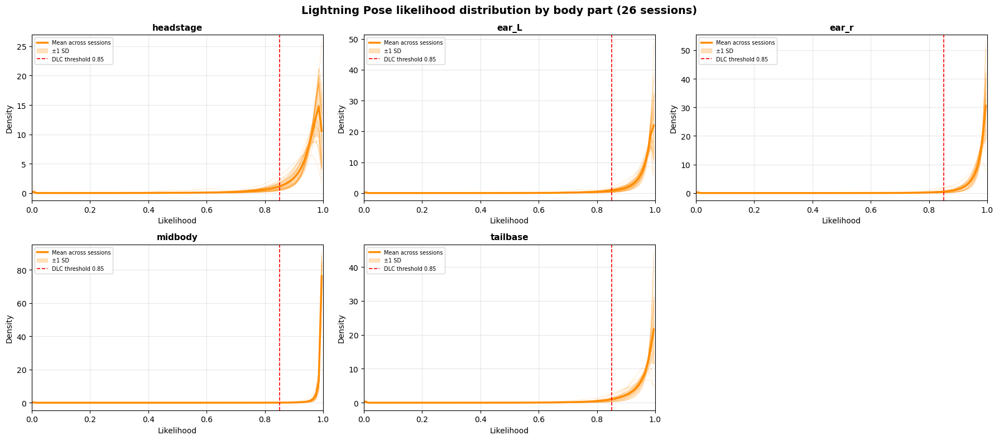

In [6]:
bins = np.linspace(0, 1, 101)
bin_centers = (bins[:-1] + bins[1:]) / 2

ncols = min(3, len(BODYPARTS))
nrows = (len(BODYPARTS) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)
fig.suptitle(f"Lightning Pose likelihood distribution by body part ({len(sessions)} sessions)",
             fontsize=14, fontweight="bold")

for idx, bp in enumerate(BODYPARTS):
    ax = axes[idx // ncols][idx % ncols]
    all_hists = []
    for s in sessions:
        _, _, lik = get_xyl(s["lp"], bp)
        counts, _ = np.histogram(lik, bins=bins, density=True)
        all_hists.append(counts)
        ax.plot(bin_centers, counts, color="darkorange", lw=0.6, alpha=0.25)

    mean_hist = np.mean(all_hists, axis=0)
    std_hist = np.std(all_hists, axis=0)
    ax.plot(bin_centers, mean_hist, color="darkorange", lw=2.5, label="Mean across sessions")
    ax.fill_between(bin_centers, np.maximum(0, mean_hist - std_hist), mean_hist + std_hist,
                     color="darkorange", alpha=0.25, label="±1 SD")
    ax.axvline(LIKELIHOOD_THR, color="red", lw=1.2, ls="--", label=f"DLC threshold {LIKELIHOOD_THR}")

    ax.set_title(bp, fontsize=11, fontweight="bold")
    ax.set_xlabel("Likelihood")
    ax.set_ylabel("Density")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 1)

for idx in range(len(BODYPARTS), nrows * ncols):
    axes[idx // ncols][idx % ncols].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lp_likelihood_distribution_by_bodypart.png"), dpi=120, bbox_inches="tight")
plt.show()

Per-session breakdown for `TRAJ_BODYPART` (the point used for the trajectory
comparison below), so any session with unusually low Lightning Pose
confidence stands out before looking at trajectories.

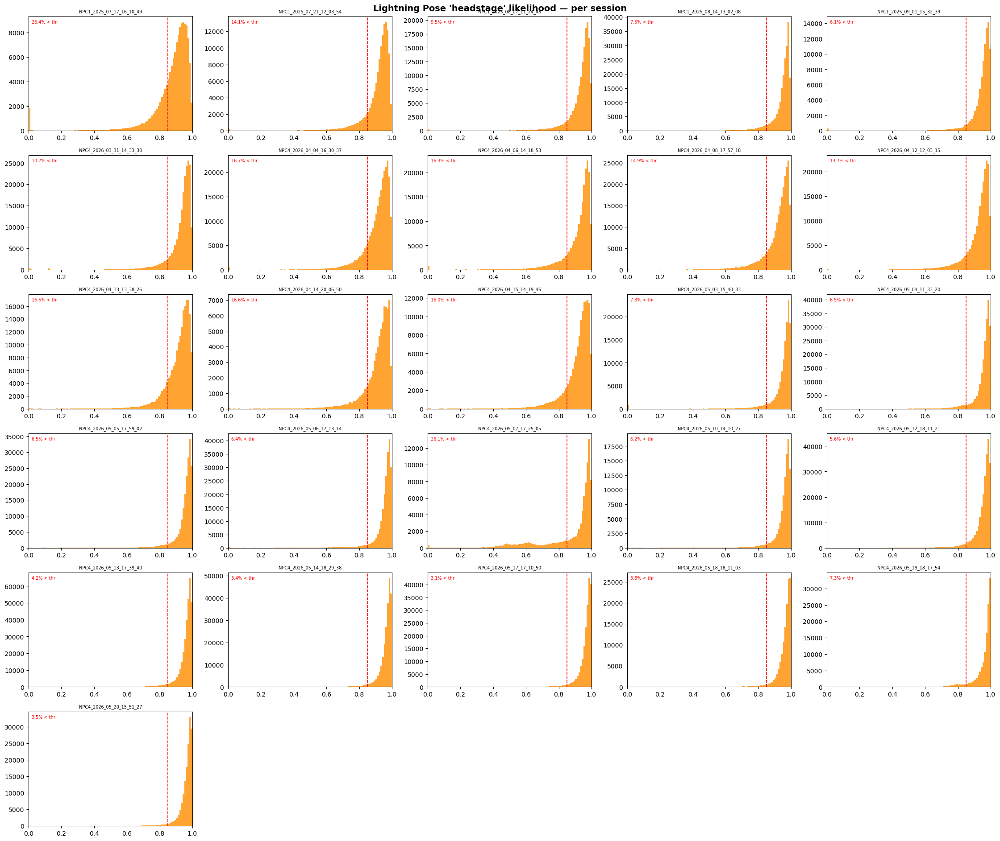

In [7]:
n_sess = len(sessions)
ncols = min(5, n_sess)
nrows = (n_sess + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows), squeeze=False)
fig.suptitle(f"Lightning Pose '{TRAJ_BODYPART}' likelihood — per session", fontsize=14, fontweight="bold")

for idx, s in enumerate(sessions):
    ax = axes[idx // ncols][idx % ncols]
    _, _, lik = get_xyl(s["lp"], TRAJ_BODYPART)
    n_low = int((lik < LIKELIHOOD_THR).sum())
    ax.hist(lik, bins=100, color="darkorange", edgecolor="none", alpha=0.8)
    ax.axvline(LIKELIHOOD_THR, color="red", lw=1.2, ls="--")
    ax.set_title(s["session_id"].split("_stitched")[0], fontsize=7)
    ax.text(0.02, 0.97, f"{100*n_low/len(lik):.1f}% < thr", transform=ax.transAxes,
            va="top", fontsize=7, color="red")
    ax.set_xlim(0, 1)

for idx in range(n_sess, nrows * ncols):
    axes[idx // ncols][idx % ncols].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"lp_likelihood_per_session_{TRAJ_BODYPART}.png"), dpi=120, bbox_inches="tight")
plt.show()

# Trajectory Comparison — DLC vs Lightning Pose
For every session with a matched DLC file, plot the `TRAJ_BODYPART`
trajectory from each tracker side by side on top of the maze background
(first frame of the video). Saved to `OUTPUT_DIR/trajectory_comparison/`.
Sessions without a DLC match are listed but skipped (Lightning Pose was run
on some sessions that were never tracked with DLC).

Skipping (no DLC data):
  NPC4_2026_03_31_14_33_30_stitched_blacked
  NPC4_2026_04_06_14_18_53_stitched_blacked
  NPC4_2026_04_08_17_57_18_stitched_blacked
  NPC4_2026_04_12_12_03_15_stitched_blacked
  NPC4_2026_04_13_13_38_26_stitched_blacked
  NPC4_2026_04_14_20_06_50_stitched_blacked
  NPC4_2026_04_15_14_19_46_stitched_blacked


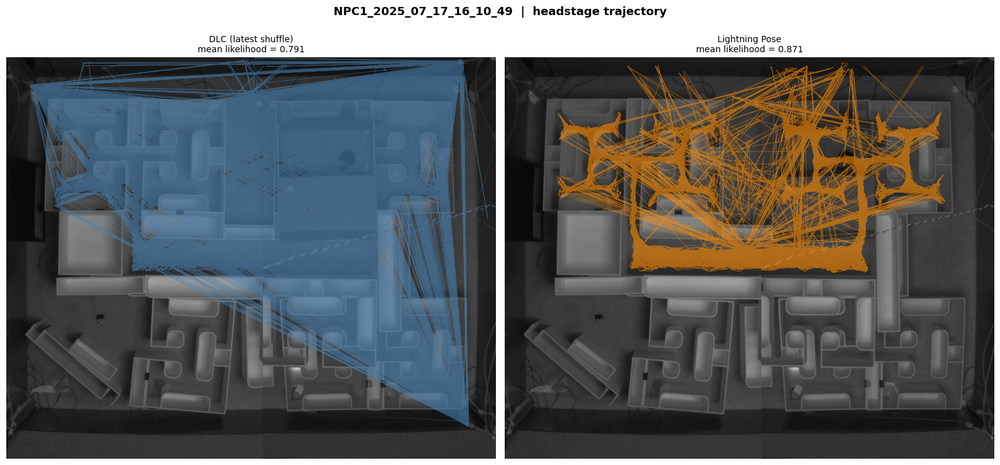

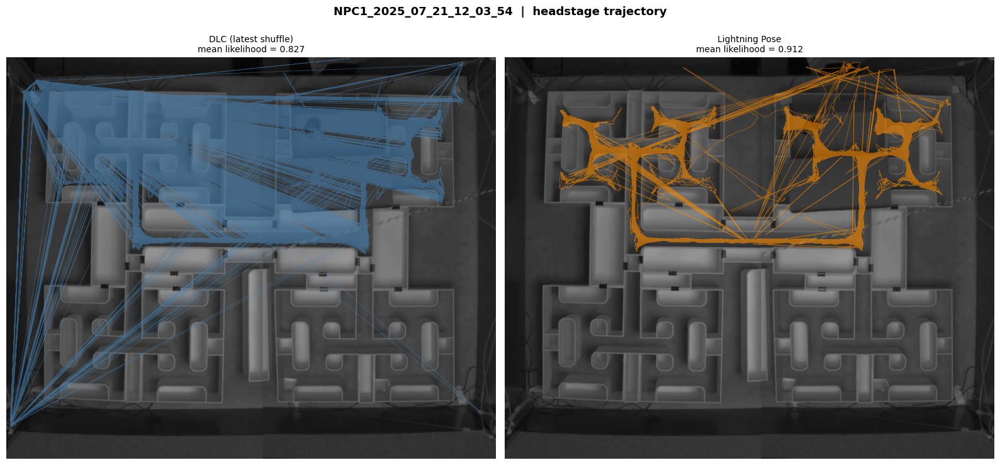

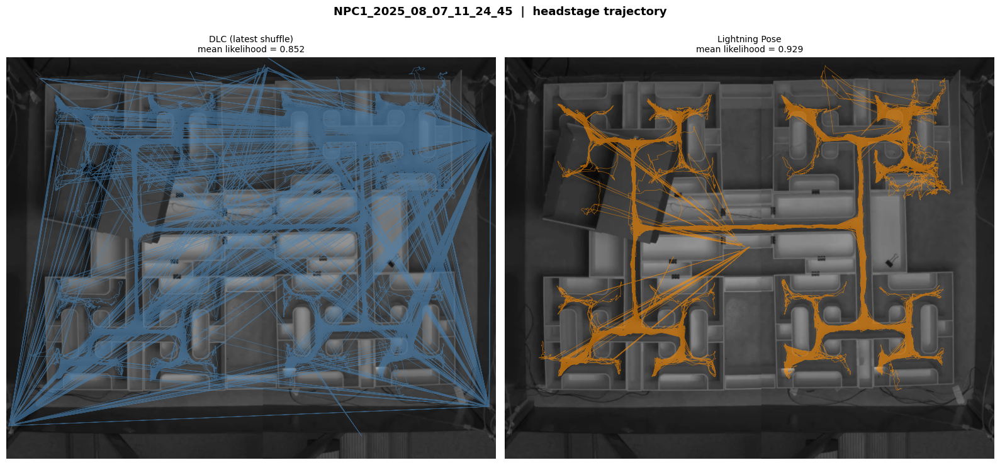

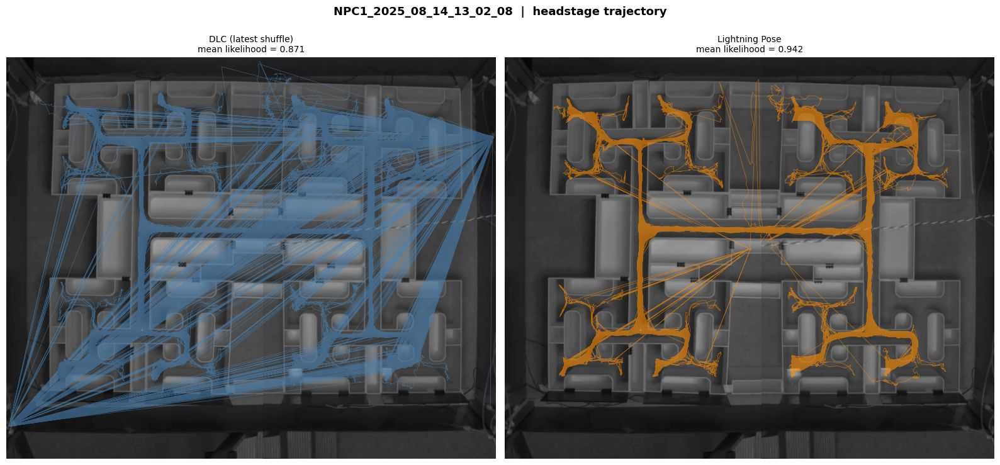

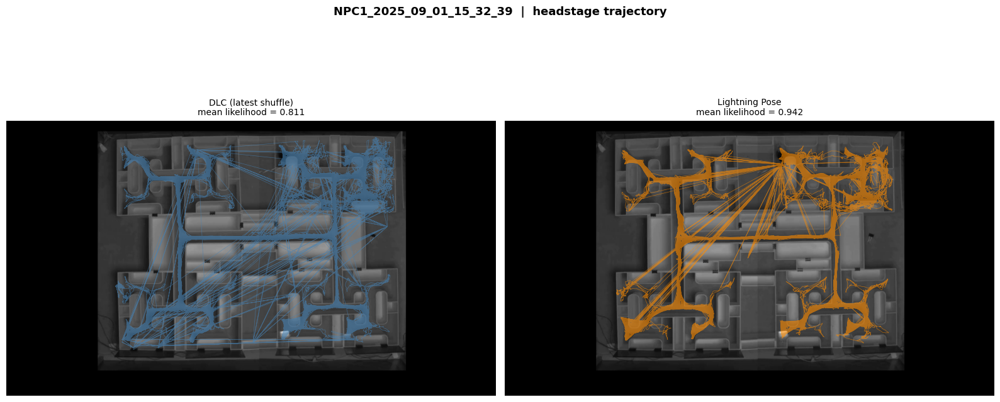

...

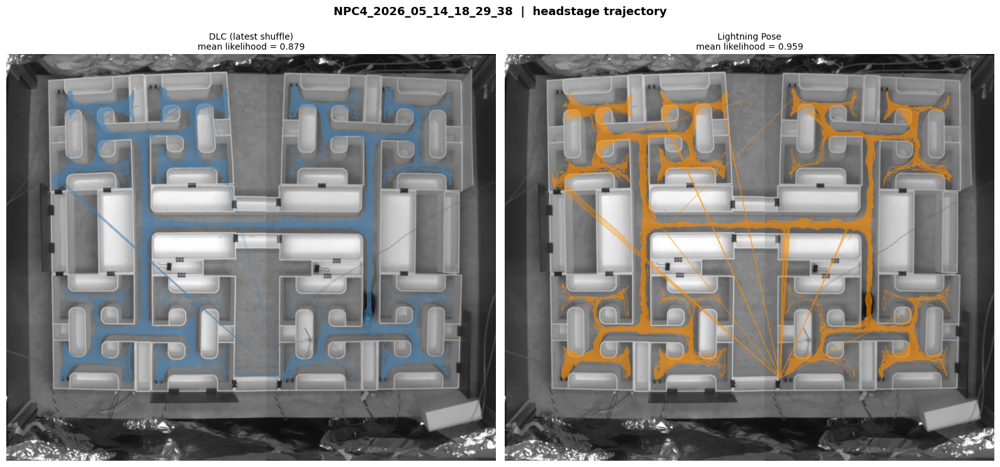

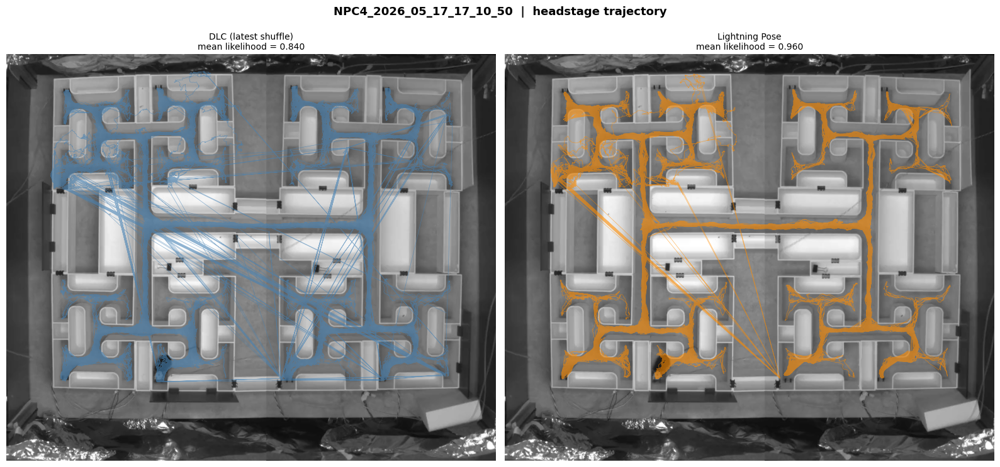

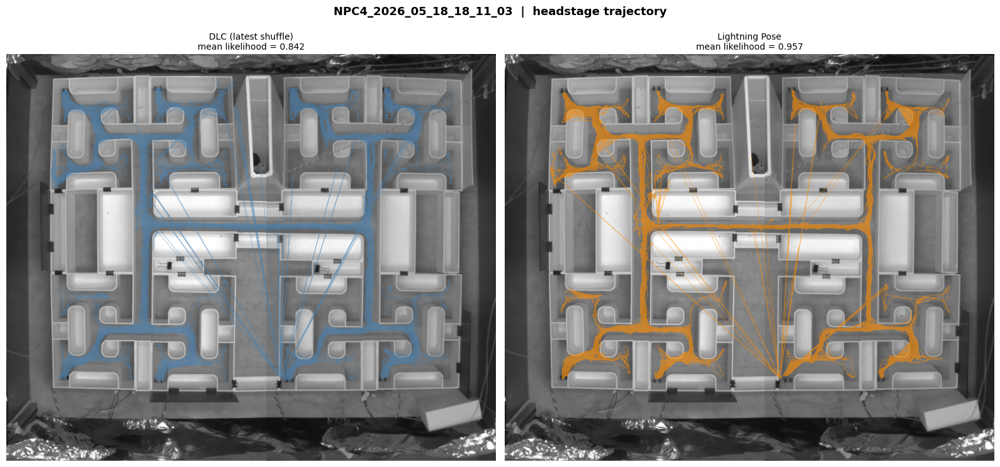

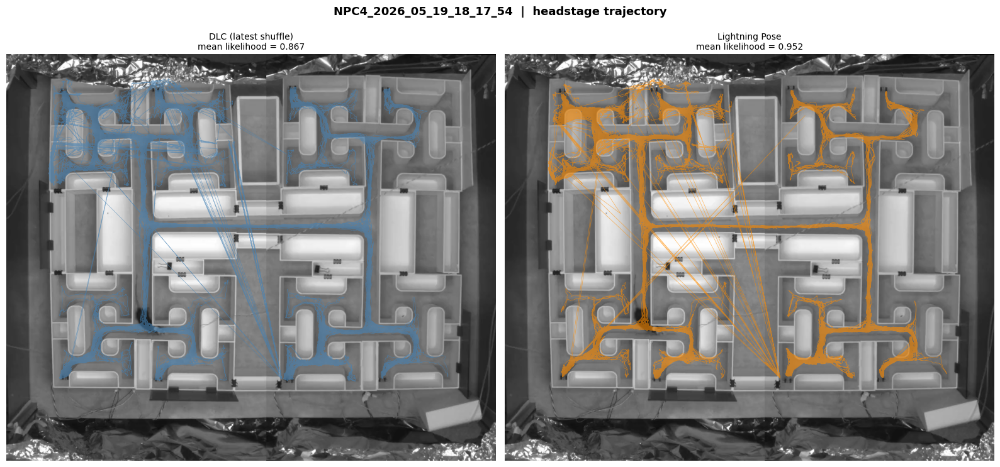

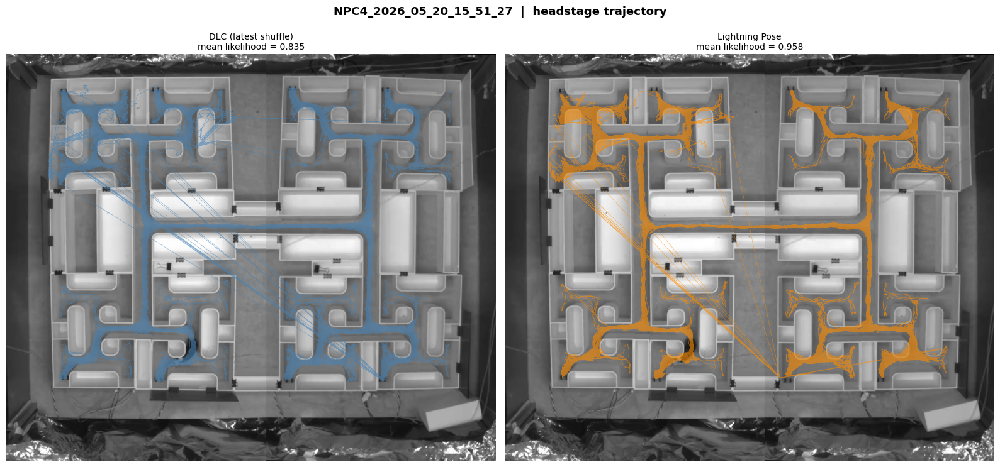


Saved trajectory comparison plots to: \\wsl.localhost\Ubuntu\home\almog\LightPose\lightning-pose\scripts\configs\outputs\2026-08-29\18-17-58\lp_vs_dlc_comparison\trajectory_comparison


In [8]:
traj_dir = os.path.join(OUTPUT_DIR, "trajectory_comparison")
os.makedirs(traj_dir, exist_ok=True)

skipped = [s["session_id"] for s in sessions if s["dlc"] is None]
if skipped:
    print("Skipping (no DLC data):")
    for sid in skipped:
        print(f"  {sid}")

for s in sessions:
    if s["dlc"] is None:
        continue

    sid = s["session_id"]
    label = sid.split("_stitched")[0]

    maze_img = None
    if s["video_path"]:
        cap = cv2.VideoCapture(s["video_path"])
        ret, frame = cap.read()
        cap.release()
        if ret:
            maze_img = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    dlc_x, dlc_y, dlc_lik = get_xyl(s["dlc"], TRAJ_BODYPART)
    lp_x, lp_y, lp_lik = get_xyl(s["lp"], TRAJ_BODYPART)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    fig.suptitle(f"{label}  |  {TRAJ_BODYPART} trajectory", fontsize=13, fontweight="bold")

    for ax, x, y, lik, title, color in (
        (axes[0], dlc_x, dlc_y, dlc_lik, "DLC (latest shuffle)", "steelblue"),
        (axes[1], lp_x, lp_y, lp_lik, "Lightning Pose", "darkorange"),
    ):
        if maze_img is not None:
            ax.imshow(maze_img)
        ax.plot(x, y, color=color, lw=0.5, alpha=0.6)
        ax.set_title(f"{title}\nmean likelihood = {np.nanmean(lik):.3f}", fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(traj_dir, f"{label}.png"), dpi=110, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print(f"\nSaved trajectory comparison plots to: {traj_dir}")